# DEPENDENCIES

In [1]:
!pip install opencv-python matplotlib scikit-learn
!pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121
!pip install torch torchvision

  Using cached matplotlib-3.10.8-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (52 kB)
  Using cached scikit_learn-1.8.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (11 kB)
  Using cached contourpy-1.3.3-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.9/72.9 MB 10.4 MB/s  0:00:07m0:00:0100:01
Using cached matplotlib-3.10.8-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (8.7 MB)
Using cached scikit_learn-1.8.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (8.9 MB)
Using cached contourpy-1.3.3-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (362 kB)
Using cached cycler-0.

# IMPORT

In [2]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch.optim as optim
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


# PATHS

In [3]:
train_image_dir = "../dataset/DRIVE/training/images"
train_mask_dir = "../dataset/DRIVE/training/1st_manual"

test_image_dir = "../dataset/DRIVE/test/images"
test_mask_dir = "../dataset/DRIVE/test/1st_manual"

# DATASET CLASS

In [4]:
class DriveDataset(Dataset):
    
    def __init__(self, image_dir, mask_dir):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.images = sorted(os.listdir(image_dir))
        
        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Resize((256,256))
        ])
        
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):

        img_name = self.images[idx]
        img_path = os.path.join(self.image_dir, img_name)

        # Extract image index (e.g., 21 from 21_training.tif)
        number = img_name.split("_")[0]
        mask_name = number + "_manual1.gif"
        mask_path = os.path.join(self.mask_dir, mask_name)

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(mask_path, 0)

        if image is None:
            raise ValueError(f"Image not found: {img_path}")
        if mask is None:
            raise ValueError(f"Mask not found: {mask_path}")

        image = self.transform(image)
        mask = self.transform(mask)

        mask = (mask > 0).float()

        return image, mask

# LOAD DATASET

In [5]:
train_dataset = DriveDataset(train_image_dir, train_mask_dir)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)

print("Training images:", len(train_dataset))

Training images: 20


# VISUALIZE SAMPLE

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000002].


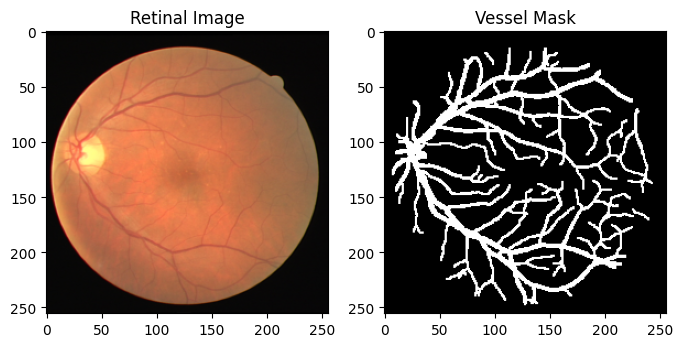

In [6]:
image, mask = train_dataset[0]

plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.title("Retinal Image")
plt.imshow(image.permute(1,2,0))

plt.subplot(1,2,2)
plt.title("Vessel Mask")
plt.imshow(mask.squeeze(), cmap="gray")

plt.show()

# U-NET MODEL

In [ ]:
class DoubleConv(nn.Module):
    
    def __init__(self, in_channels, out_channels):
        super().__init__()
        
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels,out_channels,3,padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels,out_channels,3,padding=1),
            nn.ReLU(inplace=True)
        )
        
    def forward(self,x):
        return self.conv(x)


class UNet(nn.Module):
    
    def __init__(self):
        super().__init__()
        
        self.down1 = DoubleConv(3,64)
        self.down2 = DoubleConv(64,128)
        self.down3 = DoubleConv(128,256)
        
        self.pool = nn.MaxPool2d(2)
        
        self.middle = DoubleConv(256,512)
        
        self.up3 = nn.ConvTranspose2d(512,256,2,stride=2)
        self.conv3 = DoubleConv(512,256)
        
        self.up2 = nn.ConvTranspose2d(256,128,2,stride=2)
        self.conv2 = DoubleConv(256,128)
        
        self.up1 = nn.ConvTranspose2d(128,64,2,stride=2)
        self.conv1 = DoubleConv(128,64)
        
        self.out = nn.Conv2d(64,1,1)
        
    def forward(self,x):
        
        d1 = self.down1(x)
        p1 = self.pool(d1)
        
        d2 = self.down2(p1)
        p2 = self.pool(d2)
        
        d3 = self.down3(p2)
        p3 = self.pool(d3)
        
        m = self.middle(p3)
        
        u3 = self.up3(m)
        u3 = torch.cat([u3,d3],dim=1)
        u3 = self.conv3(u3)
        
        u2 = self.up2(u3)
        u2 = torch.cat([u2,d2],dim=1)
        u2 = self.conv2(u2)
        
        u1 = self.up1(u2)
        u1 = torch.cat([u1,d1],dim=1)
        u1 = self.conv1(u1)
        
        return torch.sigmoid(self.out(u1))

# INITIALIZE MODEL

In [8]:
model = UNet().to(device)

optimizer = optim.Adam(model.parameters(), lr=1e-4)
loss_fn = nn.BCELoss()

print(model)

UNet(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (down3): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (middle): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(256, 512, kernel_size=(3

# DICE SCORE METRIC

In [ ]:
def dice_score(pred, target):
    
    smooth = 1e-6
    
    pred = pred.view(-1)
    target = target.view(-1)
    
    intersection = (pred * target).sum()
    
    return (2*intersection + smooth) / (pred.sum() + target.sum() + smooth)

def intersection_over_union(pred, target):
    smooth = 1e-6
    pred = pred.view(-1)
    target = target.view(-1)
    intersection = (pred * target).sum()
    union = pred.sum() + target.sum() - intersection
    return (intersection + smooth) / (union + smooth)


# TRAINING LOOP

In [ ]:
epochs = 1000

for epoch in range(epochs):
    
    model.train()
    epoch_loss = 0
    epoch_dice = 0
    epoch_iou = 0
    
    for images, masks in train_loader:
        
        images = images.to(device)
        masks = masks.to(device)
        
        preds = model(images)
        
        loss = loss_fn(preds, masks)


        dice = dice_score(preds, masks)
        iou = intersection_over_union(preds, masks)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        
    print(f"Epoch {epoch+1}/{epochs} Loss: {epoch_loss/len(train_loader):.4f} Dice: {epoch_dice/len(train_loader):.4f} IoU: {epoch_iou/len(train_loader):.4f}")

Epoch 1/1000  Loss: 0.6958
Epoch 2/1000  Loss: 0.6869
Epoch 3/1000  Loss: 0.6745
Epoch 4/1000  Loss: 0.6549
Epoch 5/1000  Loss: 0.6102
Epoch 6/1000  Loss: 0.5619
Epoch 7/1000  Loss: 0.5446
Epoch 8/1000  Loss: 0.5271
Epoch 9/1000  Loss: 0.5076
Epoch 10/1000  Loss: 0.4875
Epoch 11/1000  Loss: 0.4623
Epoch 12/1000  Loss: 0.4393
Epoch 13/1000  Loss: 0.4283
Epoch 14/1000  Loss: 0.4254
Epoch 15/1000  Loss: 0.4244
Epoch 16/1000  Loss: 0.4228
Epoch 17/1000  Loss: 0.4211
Epoch 18/1000  Loss: 0.4202
Epoch 19/1000  Loss: 0.4201
Epoch 20/1000  Loss: 0.4193
Epoch 21/1000  Loss: 0.4186
Epoch 22/1000  Loss: 0.4182
Epoch 23/1000  Loss: 0.4175
Epoch 24/1000  Loss: 0.4172
Epoch 25/1000  Loss: 0.4168
Epoch 26/1000  Loss: 0.4163
Epoch 27/1000  Loss: 0.4162
Epoch 28/1000  Loss: 0.4164
Epoch 29/1000  Loss: 0.4164
Epoch 30/1000  Loss: 0.4160
Epoch 31/1000  Loss: 0.4154
Epoch 32/1000  Loss: 0.4150
Epoch 33/1000  Loss: 0.4149
Epoch 34/1000  Loss: 0.4143
Epoch 35/1000  Loss: 0.4144
Epoch 36/1000  Loss: 0.4145
E

# PREDICTION

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000002].


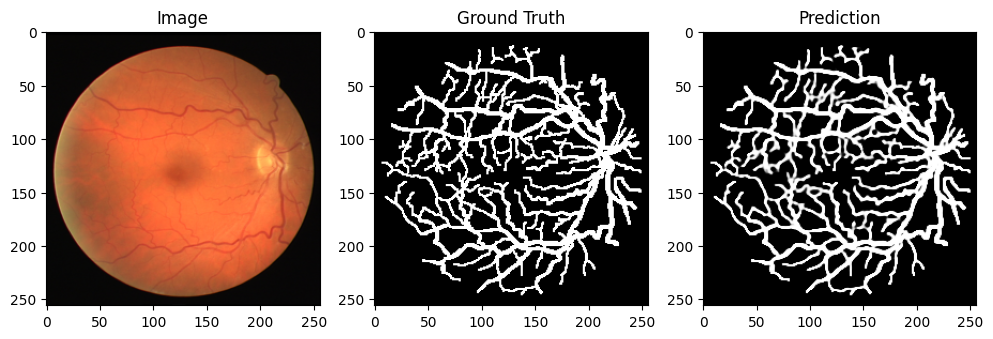

In [11]:
model.eval()

image, mask = train_dataset[1]

with torch.no_grad():
    
    pred = model(image.unsqueeze(0).to(device))
    pred = pred.squeeze().cpu().numpy()

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.title("Image")
plt.imshow(image.permute(1,2,0))

plt.subplot(1,3,2)
plt.title("Ground Truth")
plt.imshow(mask.squeeze(), cmap="gray")

plt.subplot(1,3,3)
plt.title("Prediction")
plt.imshow(pred, cmap="gray")

plt.show()

# SAVE MODEL

In [12]:
torch.save(model.state_dict(), "unet_drive.pth")